# LAB2 - Bài 4

## Nhập dữ liệu

In [28]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn import tree
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

In [29]:
data = pd.read_csv('./Dataset/winequality-red.csv')

In [30]:
data.head()

,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


Đặng Phan Duy - 6451071010

In [31]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 12 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   fixed acidity         1599 non-null   float64
 1   volatile acidity      1599 non-null   float64
 2   citric acid           1599 non-null   float64
 3   residual sugar        1599 non-null   float64
 4   chlorides             1599 non-null   float64
 5   free sulfur dioxide   1599 non-null   float64
 6   total sulfur dioxide  1599 non-null   float64
 7   density               1599 non-null   float64
 8   pH                    1599 non-null   float64
 9   sulphates             1599 non-null   float64
 10  alcohol               1599 non-null   float64
 11  quality               1599 non-null   int64  
dtypes: float64(11), int64(1)
memory usage: 150.0 KB


Đặng Phan Duy - 6451071010

In [32]:
data.isnull().sum()

fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64

Đặng Phan Duy - 6451071010

In [33]:
data['quality'].value_counts().sort_index()

quality
3     10
4     53
5    681
6    638
7    199
8     18
Name: count, dtype: int64

Đặng Phan Duy - 6451071010

## Câu 3

<Axes: >

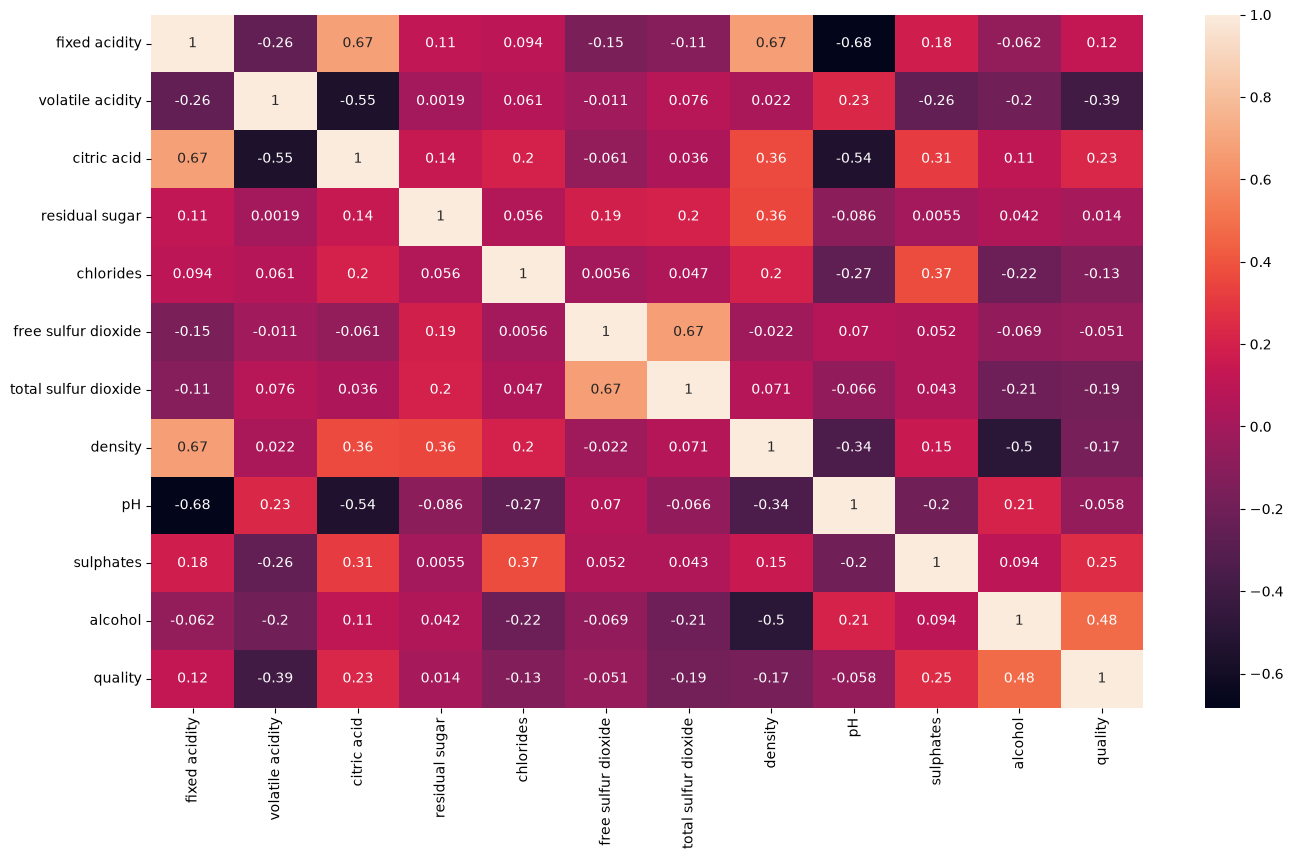

In [34]:
plt.figure(figsize=(16,9))
sns.heatmap(data.corr(method='pearson'), annot=True)

Đặng Phan Duy - 6451071010

In [35]:
# Liệt kê các cặp thuộc tính có độ tương đồng cao (|r| > 0.65)
corr = data.drop('quality', axis=1).corr(method='pearson')
high_corr = [(corr.index[i], corr.columns[j], round(corr.iloc[i, j], 3))
             for i in range(len(corr)) for j in range(i + 1, len(corr))
             if abs(corr.iloc[i, j]) > 0.65]
pd.DataFrame(high_corr, columns=['Thuộc tính 1', 'Thuộc tính 2', 'Pearson'])

,Thuộc tính 1,Thuộc tính 2,Pearson
0,fixed acidity,citric acid,0.672
1,fixed acidity,density,0.668
2,fixed acidity,pH,-0.683
3,free sulfur dioxide,total sulfur dioxide,0.668


Đặng Phan Duy - 6451071010

Nhận xét: có 4 cặp thuộc tính có độ tương đồng cao (|r| ≈ 0.67 - 0.68):
- 'fixed acidity' tương đồng cao với 3 thuộc tính 'citric acid', 'density' và 'pH' nên loại bỏ cột 'fixed acidity'.
- 'free sulfur dioxide' tương đồng cao với 'total sulfur dioxide' (lượng SO2 tự do là một phần của tổng SO2) nên loại bỏ cột 'free sulfur dioxide'.

In [36]:
data = data.drop(['fixed acidity', 'free sulfur dioxide'], axis=1)
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1599 entries, 0 to 1598
Data columns (total 10 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   volatile acidity      1599 non-null   float64
 1   citric acid           1599 non-null   float64
 2   residual sugar        1599 non-null   float64
 3   chlorides             1599 non-null   float64
 4   total sulfur dioxide  1599 non-null   float64
 5   density               1599 non-null   float64
 6   pH                    1599 non-null   float64
 7   sulphates             1599 non-null   float64
 8   alcohol               1599 non-null   float64
 9   quality               1599 non-null   int64  
dtypes: float64(9), int64(1)
memory usage: 125.1 KB


Đặng Phan Duy - 6451071010

## Câu 4

In [37]:
features = data.drop('quality', axis=1)
labels = data['quality']

## Câu 5

In [38]:
features.select_dtypes(exclude=['number']).columns

Index([], dtype='object')

Đặng Phan Duy - 6451071010

Nhận xét: tất cả các thuộc tính đều đã ở dạng số nên không cần chuyển đổi về dạng one-hot vector.

## Câu 6

In [39]:
X = features
y = labels
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [40]:
print("Number of training data:", len(X_train))
print("Number of test data:", len(X_test))

Number of training data: 1119
Number of test data: 480


Đặng Phan Duy - 6451071010

## Câu 7

In [41]:
clf = tree.DecisionTreeClassifier(criterion="entropy", random_state=0)
#Train Decision Tree Classifer
clf.fit(X_train, y_train)

,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'entropy'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of sampl

Đặng Phan Duy - 6451071010

In [42]:
#Predict the response for test dataset
tree_pred = clf.predict(X_test)

# Model Accuracy, how often is the classifier correct?
tree_score = metrics.accuracy_score(y_test, tree_pred)
print("Accuracy:", tree_score)
print("Report:", metrics.classification_report(y_test, tree_pred, zero_division=0))

Accuracy: 0.5770833333333333
Report:               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.04      0.06      0.05        17
           5       0.68      0.63      0.65       195
           6       0.58      0.60      0.59       200
           7       0.49      0.51      0.50        61
           8       0.29      0.33      0.31         6

    accuracy                           0.58       480
   macro avg       0.35      0.36      0.35       480
weighted avg       0.59      0.58      0.58       480



Đặng Phan Duy - 6451071010

In [43]:
tree_cm = metrics.confusion_matrix(y_test, tree_pred, labels=clf.classes_)

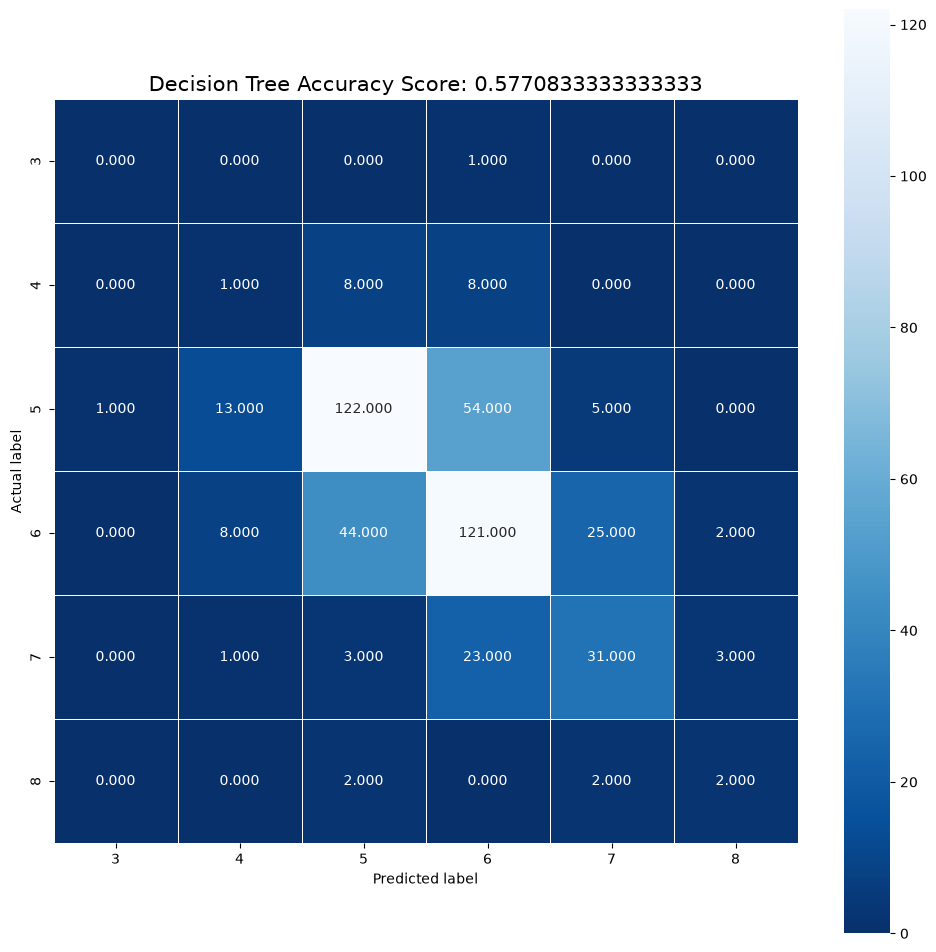

In [44]:
plt.figure(figsize=(12,12))
sns.heatmap(tree_cm, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Blues_r',
            xticklabels=clf.classes_, yticklabels=clf.classes_);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Decision Tree Accuracy Score: {0}'.format(tree_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

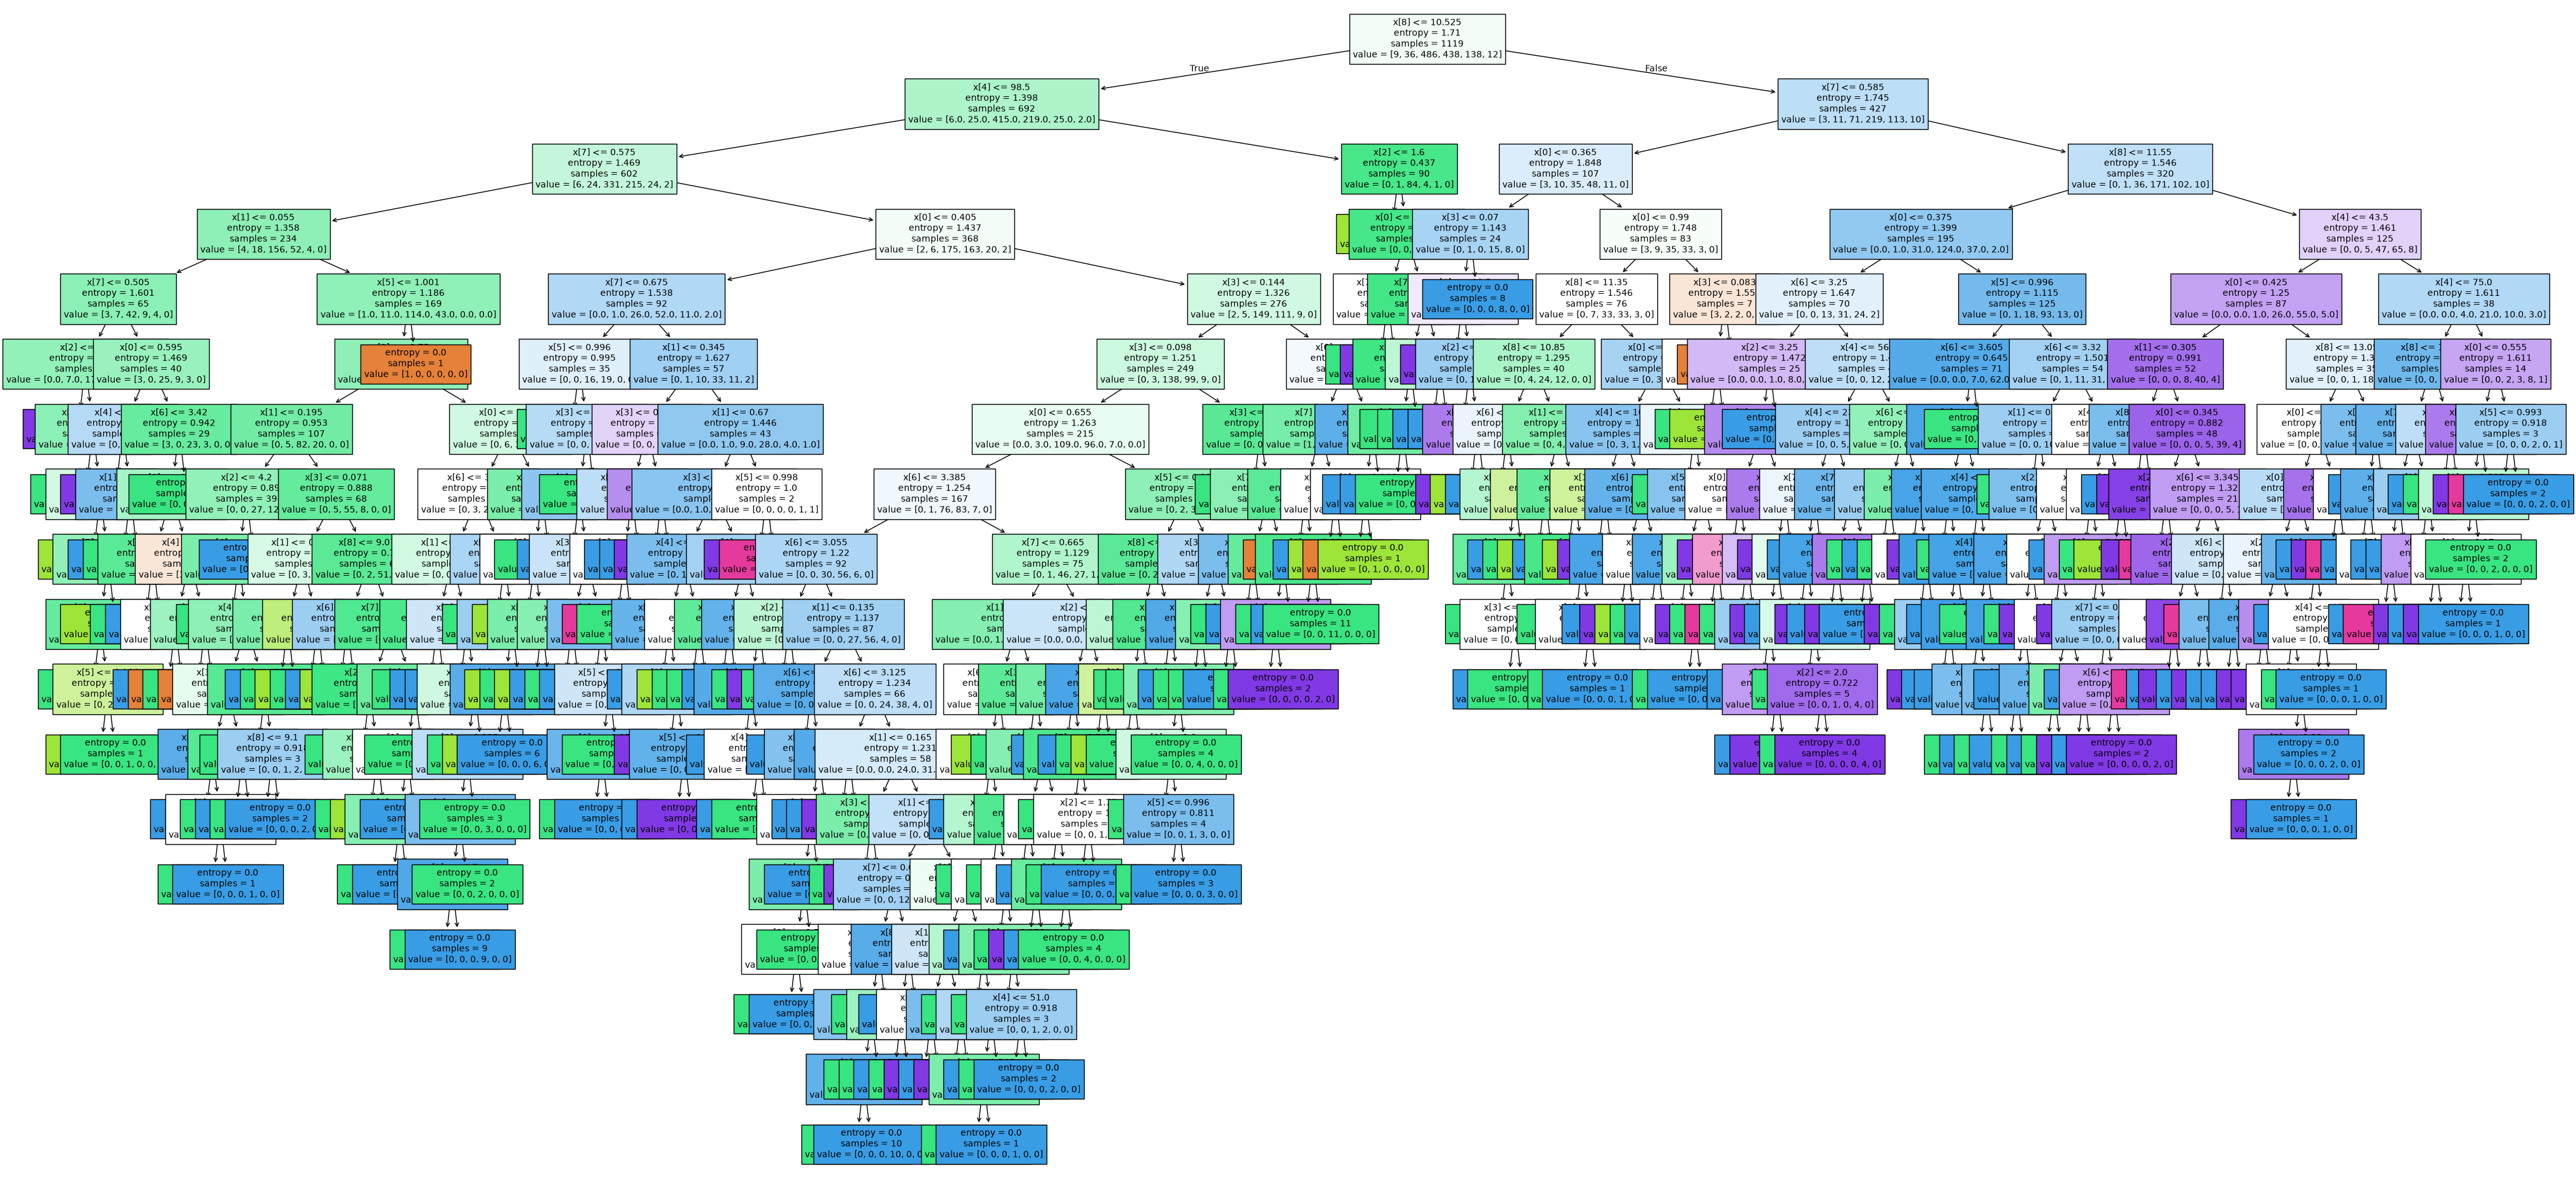

In [45]:
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf, filled=True, fontsize=10)
plt.savefig('decision_tree', dpi=100)
plt.show()

Đặng Phan Duy - 6451071010

## Câu 8

In [46]:
clf_gini = tree.DecisionTreeClassifier(criterion="gini", random_state=0)
#Train Decision Tree Classifer
clf_gini.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",0
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples 

Đặng Phan Duy - 6451071010

In [47]:
#Predict the response for test dataset
gini_pred = clf_gini.predict(X_test)

# Model Accuracy, how often is the classifier correct?
gini_score = metrics.accuracy_score(y_test, gini_pred)
print("Accuracy:", gini_score)
print("Report:", metrics.classification_report(y_test, gini_pred, zero_division=0))

Accuracy: 0.5583333333333333
Report:               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.00      0.00      0.00        17
           5       0.66      0.65      0.66       195
           6       0.55      0.56      0.56       200
           7       0.46      0.44      0.45        61
           8       0.10      0.17      0.12         6

    accuracy                           0.56       480
   macro avg       0.29      0.30      0.30       480
weighted avg       0.56      0.56      0.56       480



Đặng Phan Duy - 6451071010

In [48]:
gini_cm = metrics.confusion_matrix(y_test, gini_pred, labels=clf_gini.classes_)

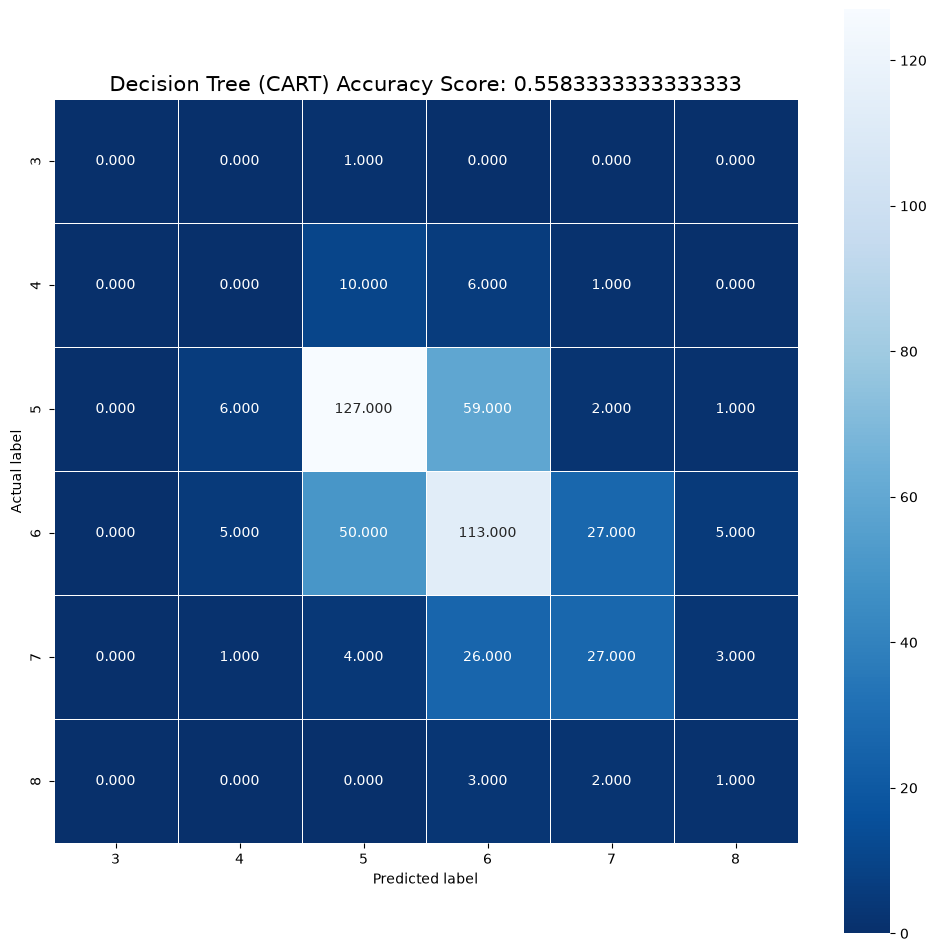

In [49]:
plt.figure(figsize=(12,12))
sns.heatmap(gini_cm, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Blues_r',
            xticklabels=clf_gini.classes_, yticklabels=clf_gini.classes_);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Decision Tree (CART) Accuracy Score: {0}'.format(gini_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

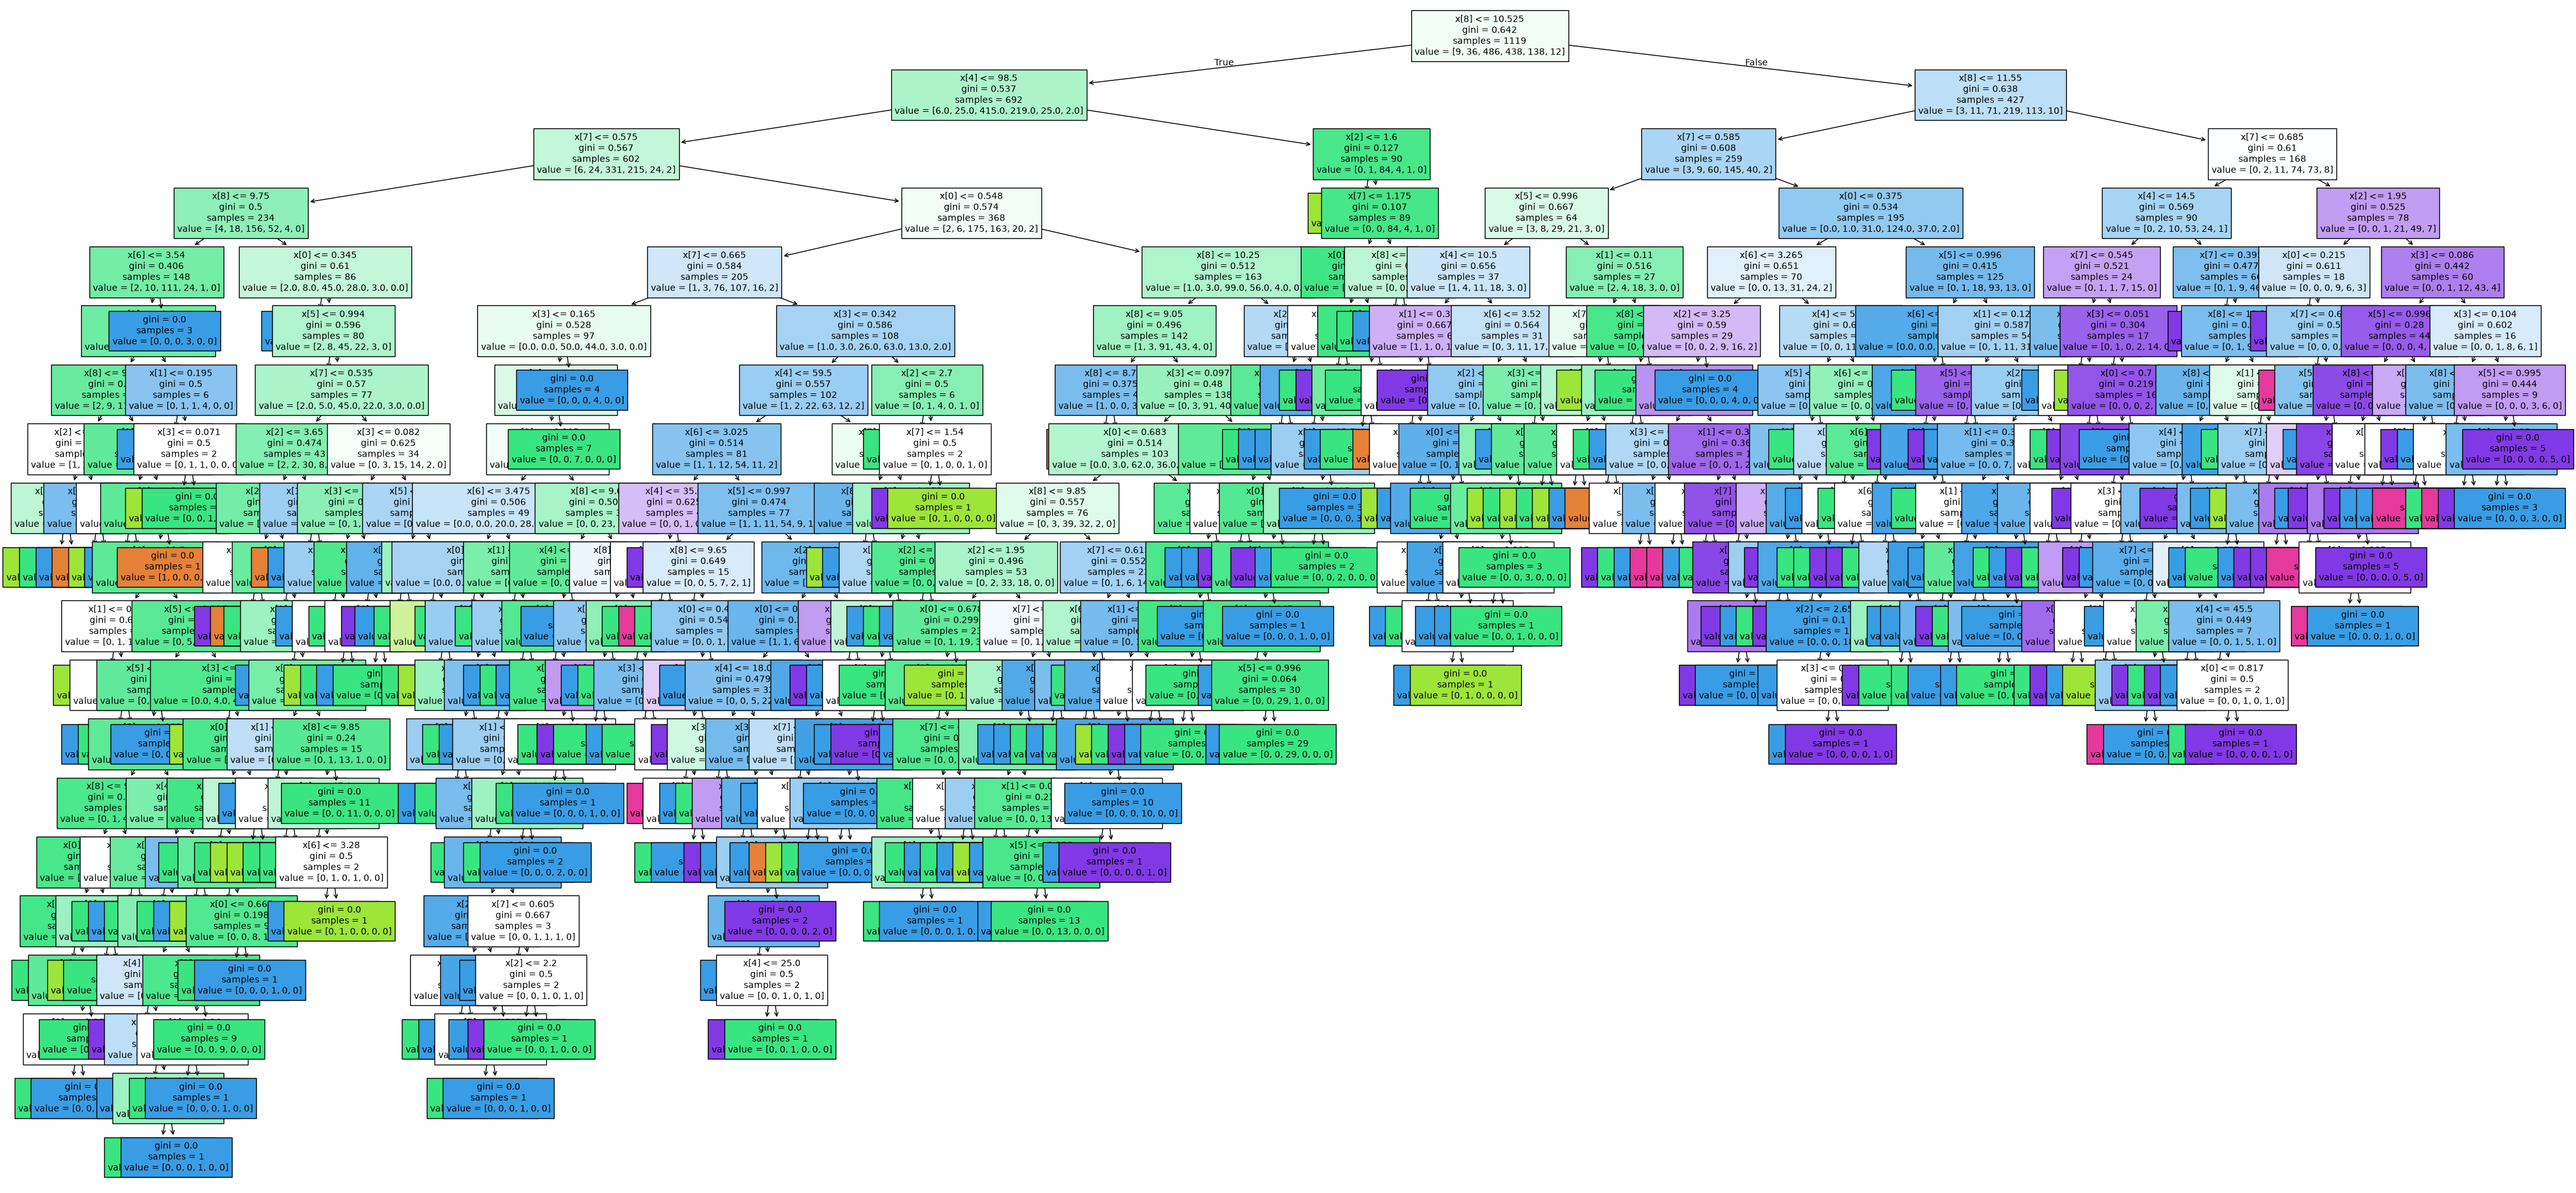

In [50]:
fig, ax = plt.subplots(figsize=(50, 24))
tree.plot_tree(clf_gini, filled=True, fontsize=10)
plt.savefig('decision_tree_gini', dpi=100)
plt.show()

Đặng Phan Duy - 6451071010

## Câu 9

In [51]:
gnb = GaussianNB()
bayes_pred = gnb.fit(X_train, y_train).predict(X_test)

In [52]:
# Model Accuracy, how often is the classifier correct?
bayes_score = metrics.accuracy_score(y_test, bayes_pred)
print("Accuracy:", bayes_score)
print("Report:", metrics.classification_report(y_test, bayes_pred, zero_division=0))

Accuracy: 0.5416666666666666
Report:               precision    recall  f1-score   support

           3       0.00      0.00      0.00         1
           4       0.06      0.06      0.06        17
           5       0.69      0.62      0.65       195
           6       0.52      0.57      0.54       200
           7       0.38      0.41      0.39        61
           8       0.00      0.00      0.00         6

    accuracy                           0.54       480
   macro avg       0.27      0.28      0.27       480
weighted avg       0.55      0.54      0.54       480



Đặng Phan Duy - 6451071010

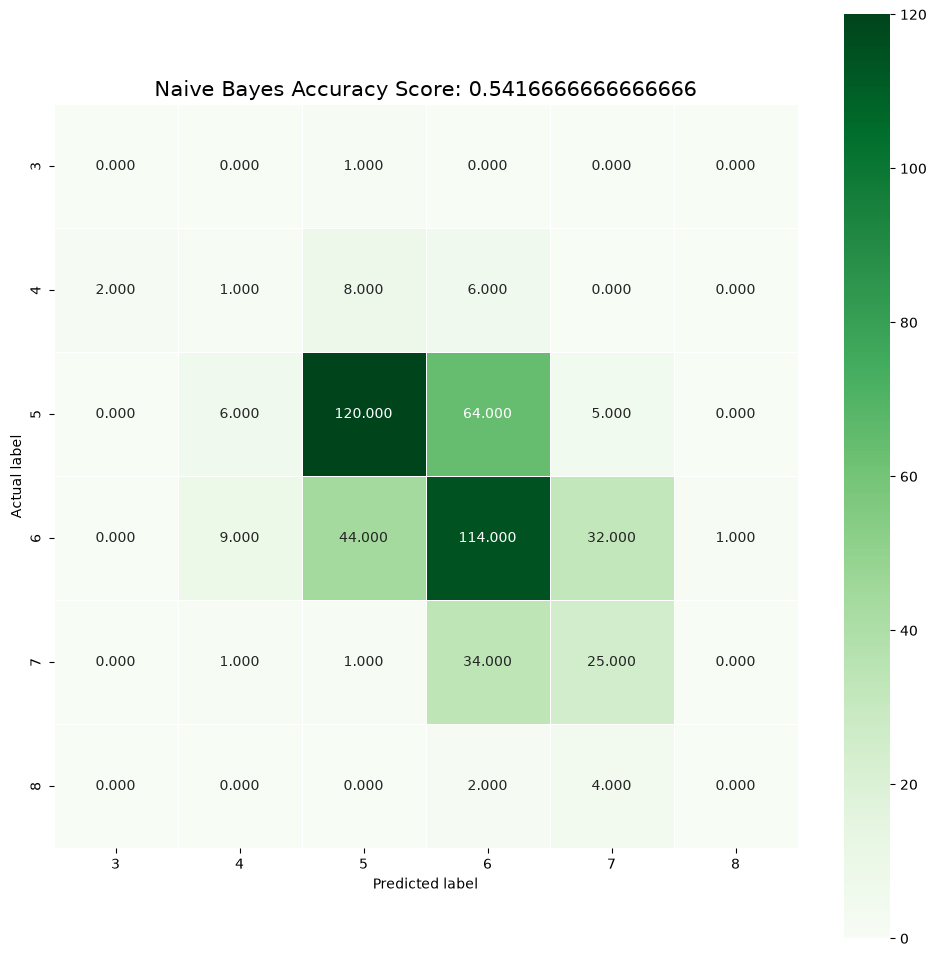

In [53]:
bayes_cm = metrics.confusion_matrix(y_test, bayes_pred, labels=gnb.classes_)

plt.figure(figsize=(12,12))
sns.heatmap(bayes_cm, annot=True, fmt=".3f", linewidths=.5, square = True, cmap = 'Greens',
            xticklabels=gnb.classes_, yticklabels=gnb.classes_);
plt.ylabel('Actual label');
plt.xlabel('Predicted label');
title = 'Naive Bayes Accuracy Score: {0}'.format(bayes_score)
plt.title(title, size = 15);

Đặng Phan Duy - 6451071010

## Câu 10

In [54]:
preds = [tree_pred, gini_pred, bayes_pred]
results = pd.DataFrame({
    'Model': ['ID3', 'CART', 'Naive Bayes'],
    'Accuracy': [metrics.accuracy_score(y_test, p) for p in preds],
    'Precision (macro)': [metrics.precision_score(y_test, p, average='macro', zero_division=0) for p in preds],
    'Recall (macro)': [metrics.recall_score(y_test, p, average='macro', zero_division=0) for p in preds],
    'Precision (weighted)': [metrics.precision_score(y_test, p, average='weighted', zero_division=0) for p in preds],
    'Recall (weighted)': [metrics.recall_score(y_test, p, average='weighted', zero_division=0) for p in preds]
})
results

,Model,Accuracy,Precision (macro),Recall (macro),Precision (weighted),Recall (weighted)
0,ID3,0.577083,0.347894,0.355166,0.588089,0.577083
1,CART,0.558333,0.294163,0.304262,0.555580,0.558333
2,Naive Bayes,0.541667,0.274241,0.275674,0.546302,0.541667


Đặng Phan Duy - 6451071010

Nhận xét:

- Cả ba mô hình đều cho độ chính xác không cao trên dữ liệu Red Wine Quality: cây ID3 đạt cao nhất (≈ 0.577), tiếp theo là cây CART (≈ 0.558) và thấp nhất là Naïve Bayes (≈ 0.542). Precision và recall (macro lẫn weighted) cũng theo đúng thứ tự này, nên trên dữ liệu này ID3 là mô hình tốt nhất.
- Nguyên nhân chính là dữ liệu bị mất cân bằng nặng: phần lớn mẫu có quality là 5 và 6 (681 và 638 mẫu), trong khi quality 3 và 8 chỉ có 10 và 18 mẫu (trong tập kiểm thử chỉ có 1 và 6 mẫu). Vì vậy cả ba mô hình chỉ dự đoán tương đối tốt các lớp 5, 6 (precision, recall khoảng 0.52 - 0.69), còn các lớp 3, 4, 8 gần như không dự đoán đúng (precision, recall ≈ 0). Điều này khiến các giá trị macro avg rất thấp (≈ 0.27 - 0.36).
- Các lỗi dự đoán chủ yếu nằm ở những lớp chất lượng liền kề nhau (ví dụ 5 bị đoán thành 6 và ngược lại) do các chỉ số hóa lý của những mẫu này khá giống nhau.
- Naïve Bayes thấp nhất vì giả định các thuộc tính độc lập và tuân theo phân phối chuẩn, trong khi các chỉ số hóa lý của rượu vẫn còn liên hệ với nhau (ví dụ density với alcohol). Hai cây quyết định phát triển đến khi các nút lá thuần nhất nên dễ bị quá khớp (overfitting); có thể cải thiện bằng cách giới hạn độ sâu (max_depth), gom nhóm quality thành ít lớp hơn (ví dụ tốt/không tốt) hoặc cân bằng lại dữ liệu.